## App User Behavior Segmentation Using Unsupervised Machine Learning

### Data loading



In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ydata_profiling import ProfileReport

C:\Users\varsh\AppData\Local\Temp\ipykernel_4740\3468818502.py:5: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


In [3]:
df= pd.read_csv("app_user_behavior_dataset.csv")

In [4]:
df2= df.copy()

In [4]:
df.shape

(50000, 25)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   user_id                        50000 non-null  int64  
 1   age                            50000 non-null  int64  
 2   gender                         50000 non-null  object 
 3   country                        50000 non-null  object 
 4   device_type                    50000 non-null  object 
 5   app_version                    50000 non-null  float64
 6   sessions_per_week              50000 non-null  int64  
 7   avg_session_duration_min       50000 non-null  float64
 8   daily_active_minutes           50000 non-null  float64
 9   feature_clicks_per_session     50000 non-null  int64  
 10  notifications_opened_per_week  50000 non-null  int64  
 11  in_app_search_count            50000 non-null  int64  
 12  pages_viewed_per_session       50000 non-null 

In [6]:
df.describe()

,user_id,age,app_version,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,notifications_opened_per_week,in_app_search_count,pages_viewed_per_session,crash_events_last_30_days,support_tickets_raised,days_since_last_login,ads_clicked_last_30_days,content_downloads,social_shares,rating_given,churn_risk_score,engagement_score,account_age_days
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,44978.000000,50000.000000,50000.000000,50000.000000
mean,124999.500000,38.513040,1.476126,7.999680,13.149842,45.164537,12.013920,4.99662,3.999060,13.470760,0.397520,0.19666,22.038240,5.995800,3.002260,2.001440,3.630664,0.500834,64.940409,603.785100
std,14433.901067,12.094948,0.470158,2.829438,8.946944,19.505118,3.480289,2.23518,1.997763,6.343635,0.633992,0.44442,12.985237,2.453313,1.731818,1.413435,1.087339,0.288578,14.838827,345.567524
min,100000.000000,18.000000,1.000000,0.000000,0.060000,5.000000,1.000000,0.00000,0.000000,3.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,10.000000,7.000000
25%,112499.750000,28.000000,1.100000,6.000000,6.570000,31.650000,10.000000,3.00000,3.000000,8.000000,0.000000,0.00000,11.000000,4.000000,2.000000,1.000000,3.000000,0.250000,54.900000,302.000000
50%,124999.500000,39.000000,1.200000,8.000000,11.240000,45.210000,12.000000,5.00000,4.000000,13.000000,0.000000,0.00000,22.000000,6.000000,3.000000,2.000000,4.000000,0.500000,65.025000,604.000000
75%,137499.250000,49.000000,2.000000,10.000000,17.570000,58.440000,14.000000,6.00000,5.000000,19.000000,1.000000,0.00000,33.000000,8.000000,4.000000,3.000000,4.000000,0.750000,75.090000,906.000000
max,149999.000000,59.000000,2.100000,26.000000,91.400000,129.130000,28.000000,16.00000,19.000000,24.000000,5.000000,4.00000,44.000000,19.000000,13.000000,11.000000,5.000000,1.000000,100.000000,1199.000000


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.isnull().mean()*100

user_id                           0.000
age                               0.000
gender                            0.000
country                           0.000
device_type                       0.000
app_version                       0.000
sessions_per_week                 0.000
avg_session_duration_min          0.000
daily_active_minutes              0.000
feature_clicks_per_session        0.000
notifications_opened_per_week     0.000
in_app_search_count               0.000
pages_viewed_per_session          0.000
crash_events_last_30_days         0.000
support_tickets_raised            0.000
days_since_last_login             0.000
subscription_type                 0.000
ads_clicked_last_30_days          0.000
content_downloads                 0.000
social_shares                     0.000
rating_given                     10.044
churn_risk_score                  0.000
engagement_score                  0.000
account_age_days                  0.000
marketing_source                  0.000


In [9]:
df["rating_given"].head()

0    NaN
1    3.0
2    2.0
3    3.0
4    5.0
Name: rating_given, dtype: float64

In [5]:
df["rating_given"]= df["rating_given"].fillna(df["rating_given"].median())

In [11]:
df["rating_given"].isnull().sum()

np.int64(0)

In [12]:
df.select_dtypes(include="object").columns

Index(['gender', 'country', 'device_type', 'subscription_type',
       'marketing_source'],
      dtype='object')

In [6]:
cat_col=['gender', 'country', 'device_type', 'subscription_type','marketing_source']

In [14]:
df["gender"].value_counts()

gender
Female    23994
Male      23936
Other      2070
Name: count, dtype: int64

In [15]:
df2.head()

,user_id,age,gender,country,device_type,app_version,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,...,days_since_last_login,subscription_type,ads_clicked_last_30_days,content_downloads,social_shares,rating_given,churn_risk_score,engagement_score,account_age_days,marketing_source
0,100000,56,Female,India,iOS,2.1,5,3.41,52.71,13,...,20,Basic,9,5,2,NaN,0.31,55.79,1152,Referral
1,100001,46,Male,UK,iOS,1.0,8,24.44,42.03,7,...,7,Free,8,3,3,3.0,0.87,82.39,1059,Email Campaign
2,100002,32,Female,UK,iOS,1.2,12,5.34,76.69,7,...,33,Free,11,6,1,2.0,0.63,42.49,678,Google Ads
3,100003,25,Male,India,Android,2.0,5,3.98,65.38,16,...,17,Basic,6,3,1,3.0,0.43,62.81,92,Organic
4,100004,38,Male,Australia,Android,1.0,10,12.85,57.06,13,...,21,Basic,4,4,2,5.0,0.43,38.21,772,Email Campaign


In [16]:
df2.value_counts()

user_id  age  gender  country    device_type  app_version  sessions_per_week  avg_session_duration_min  daily_active_minutes  feature_clicks_per_session  notifications_opened_per_week  in_app_search_count  pages_viewed_per_session  crash_events_last_30_days  support_tickets_raised  days_since_last_login  subscription_type  ads_clicked_last_30_days  content_downloads  social_shares  rating_given  churn_risk_score  engagement_score  account_age_days  marketing_source
100001   46   Male    UK         iOS          1.0          8                  24.44                     42.03                 7                           7                              3                    7                         0                          0                       7                      Free               8                         3                  3              3.0           0.87              82.39             1059              Email Campaign      1
100002   32   Female  UK         iOS          1.2      

In [7]:
for i in ["gender","country","device_type","subscription_type", "marketing_source"]:
    print(df[i].value_counts())

gender
Female    23994
Male      23936
Other      2070
Name: count, dtype: int64
country
India        22550
USA           9115
UK            5043
Canada        3853
Australia     3498
Germany       3425
Singapore     2516
Name: count, dtype: int64
device_type
Android    27315
iOS        17662
Web         5023
Name: count, dtype: int64
subscription_type
Free       30088
Basic      12495
Premium     7417
Name: count, dtype: int64
marketing_source
Organic           17539
Google Ads        12468
Referral           7539
Facebook Ads       7463
Email Campaign     4991
Name: count, dtype: int64


In [8]:
for i in ["gender","country","device_type","subscription_type", "marketing_source"]:
    print(df[i].astype("string").str.strip().str.title())

0        Female
1          Male
2        Female
3          Male
4          Male
          ...  
49995      Male
49996    Female
49997      Male
49998      Male
49999    Female
Name: gender, Length: 50000, dtype: string
0            India
1               Uk
2               Uk
3            India
4        Australia
           ...    
49995      Germany
49996        India
49997        India
49998        India
49999    Singapore
Name: country, Length: 50000, dtype: string
0            Ios
1            Ios
2            Ios
3        Android
4        Android
          ...   
49995    Android
49996        Ios
49997        Ios
49998        Ios
49999        Web
Name: device_type, Length: 50000, dtype: string
0        Basic
1         Free
2         Free
3        Basic
4        Basic
         ...  
49995     Free
49996    Basic
49997     Free
49998     Free
49999     Free
Name: subscription_type, Length: 50000, dtype: string
0              Referral
1        Email Campaign
2            Google Ads
3 

### Exploratory Data Analysis

Text(0.5, 1.0, 'country distribution')

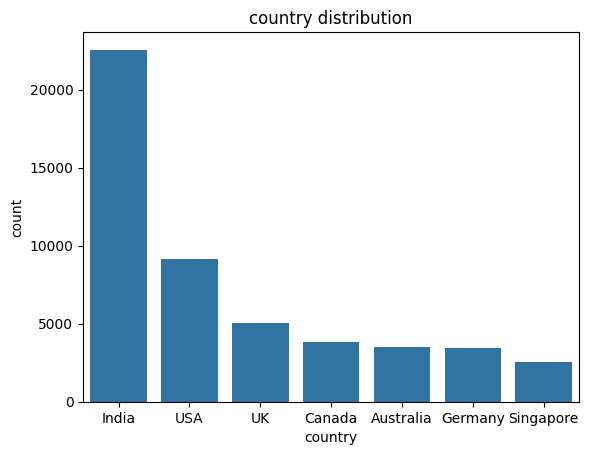

In [22]:
country_count = df["country"].value_counts()
sns.barplot(country_count)
plt.xlabel("country")
plt.ylabel("count")
plt.title("country distribution")

Text(0.5, 1.0, 'device type distribution')

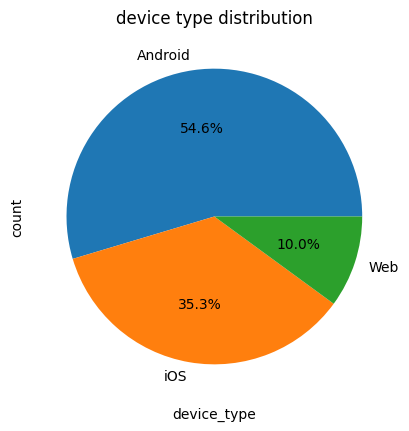

In [23]:
device_type =df["device_type"].value_counts()
plt.pie(device_type,labels=device_type.index,autopct="%1.1f%%")
plt.xlabel("device_type")
plt.ylabel("count")
plt.title("device type distribution")

Text(0.5, 1.0, ' Marketing source distribution')

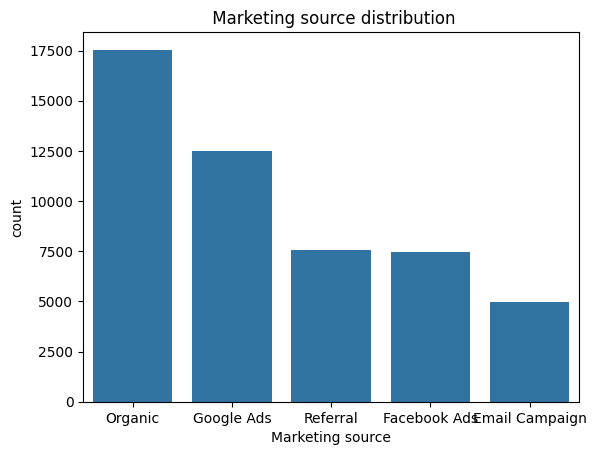

In [24]:
source_count =df["marketing_source"].value_counts()
sns.barplot(source_count)
plt.xlabel("Marketing source")
plt.ylabel("count")
plt.title(" Marketing source distribution")

Text(0.5, 1.0, 'Subscription type distribution')

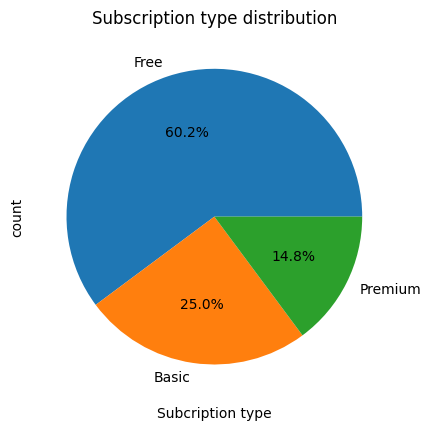

In [25]:
type_count = df["subscription_type"].value_counts()
plt.pie(type_count,labels=type_count.index, autopct="%1.1f%%")
plt.xlabel("Subcription type")
plt.ylabel("count")
plt.title("Subscription type distribution")

Text(0.5, 1.0, 'Gender distribution')

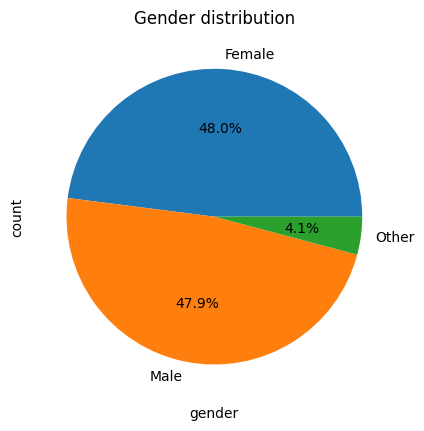

In [26]:
gender_count = df["gender"].value_counts()
plt.pie(gender_count,  labels=gender_count.index, autopct="%1.1f%%")
plt.xlabel("gender")
plt.ylabel("count")
plt.title("Gender distribution")

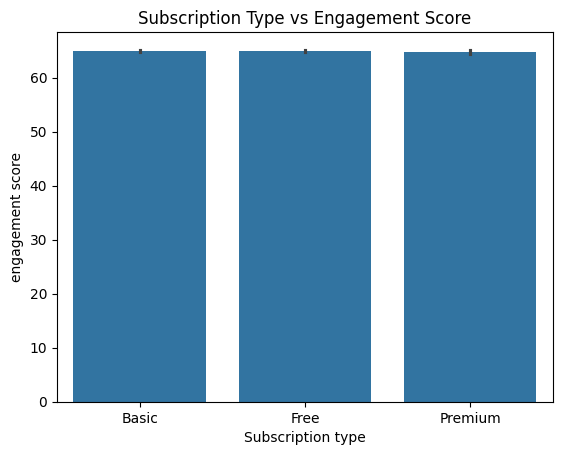

In [28]:
sns.barplot(data=df, x='subscription_type', y='engagement_score')
plt.xlabel('Subscription type')
plt.ylabel("engagement score")
plt.title("Subscription Type vs Engagement Score")
plt.show()

In [29]:
num_col=[ 'age', 'app_version', 'sessions_per_week',
       'avg_session_duration_min', 'daily_active_minutes',
       'feature_clicks_per_session', 'notifications_opened_per_week',
       'in_app_search_count', 'pages_viewed_per_session',
       'crash_events_last_30_days', 'support_tickets_raised',
       'days_since_last_login', 'ads_clicked_last_30_days',
       'content_downloads', 'social_shares', 'rating_given',
       'churn_risk_score', 'engagement_score', 'account_age_days']

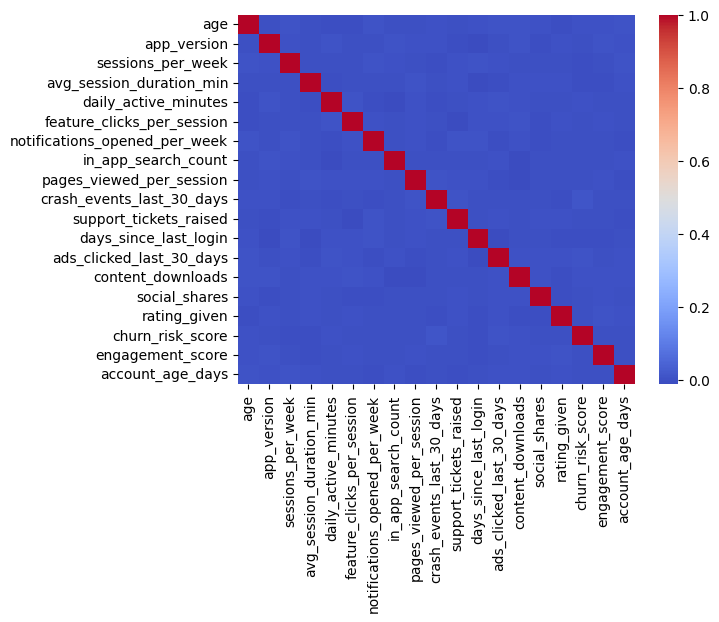

In [30]:
corr=df[num_col].corr()
sns.heatmap(data=corr, annot=False,cmap='coolwarm')
plt.show()

In [31]:
EDA= ProfileReport(df , title= "EDA")
EDA

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 25/25 [00:01<00:00, 21.14it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

### Feature Selection

In [9]:
features =['sessions_per_week', 'avg_session_duration_min', 'daily_active_minutes',
       'feature_clicks_per_session', 'notifications_opened_per_week',
       'in_app_search_count', 'pages_viewed_per_session',
       'crash_events_last_30_days',
       'days_since_last_login','ads_clicked_last_30_days', 'churn_risk_score', 'engagement_score']

In [10]:
x= df[features]

### Scaling

In [11]:
from sklearn.preprocessing import StandardScaler

In [12]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)


### Model building -KMeans clustering

#### Elbow graph

In [13]:
from sklearn.cluster import KMeans
import plotly.express as px

In [77]:
cluster=[]
wss=[]
for i in range (1, 10):
    model=KMeans(n_clusters=i,random_state=42, n_init=10)
    model.fit(x_scaled)
    cluster.append(i)
    wss.append(model.inertia_)
fig = px.line(x=cluster, y=wss)
fig.show()

In [55]:
model = KMeans(n_clusters= 4,random_state=42,n_init=10)
pred = model.fit_predict(x_scaled)

In [56]:
df["cluster"] = pred

In [68]:
df["cluster"].value_counts().sort_index()

cluster
High           6970
Low           15071
Moderate      12021
Occasional    15938
Name: count, dtype: int64

### Model evaluation

In [58]:
from sklearn.metrics import silhouette_score
score = silhouette_score(x_scaled , df["cluster"])
score

0.06195109101236301

### Cluster -level user identification & profiling

In [60]:
features = ['sessions_per_week','avg_session_duration_min', 'daily_active_minutes','feature_clicks_per_session','days_since_last_login',
    'churn_risk_score','engagement_score']
session_analysis = df.groupby("cluster")[features].mean()
session_analysis

,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,days_since_last_login,churn_risk_score,engagement_score
cluster,,,,,,,
0,7.912237,11.086605,44.976915,12.050828,21.974628,0.589683,65.032654
1,7.926282,10.237140,45.517197,12.067215,21.667507,0.742892,65.116571
2,8.135274,10.249004,44.937295,11.970950,22.659932,0.211778,64.601316
3,7.999139,29.639522,45.245202,11.933286,21.527977,0.485179,65.175795


In [61]:
df.head()

,user_id,age,gender,country,device_type,app_version,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,...,subscription_type,ads_clicked_last_30_days,content_downloads,social_shares,rating_given,churn_risk_score,engagement_score,account_age_days,marketing_source,cluster
0,100000,56,Female,India,iOS,2.1,5,3.41,52.71,13,...,Basic,9,5,2,4.0,0.31,55.79,1152,Referral,0
1,100001,46,Male,UK,iOS,1.0,8,24.44,42.03,7,...,Free,8,3,3,3.0,0.87,82.39,1059,Email Campaign,3
2,100002,32,Female,UK,iOS,1.2,12,5.34,76.69,7,...,Free,11,6,1,2.0,0.63,42.49,678,Google Ads,0
3,100003,25,Male,India,Android,2.0,5,3.98,65.38,16,...,Basic,6,3,1,3.0,0.43,62.81,92,Organic,2
4,100004,38,Male,Australia,Android,1.0,10,12.85,57.06,13,...,Basic,4,4,2,5.0,0.43,38.21,772,Email Campaign,2


In [62]:
df["cluster"] = df["cluster"].map({
    0: "Moderate",
    1: "Low",
    2: "Occasional",
    3: "High"
})

In [69]:
(df["cluster"]== 'Occasional').sum()

np.int64(15938)

In [70]:
(df["cluster"]== 'Moderate').sum()

np.int64(12021)

In [71]:
(df["cluster"]== 'High').sum()

np.int64(6970)

In [72]:
(df["cluster"]== 'Low').sum()

np.int64(15071)

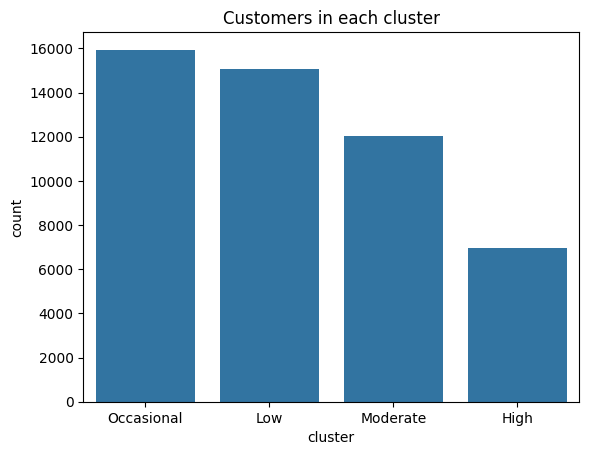

In [73]:
cluster_counts =df["cluster"].value_counts()
sns.barplot(data=cluster_counts)
plt.xlabel("cluster")
plt.ylabel("count")
plt.title("Customers in each cluster")
plt.show()

In [37]:
df.head(15)

,user_id,age,gender,country,device_type,app_version,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,...,subscription_type,ads_clicked_last_30_days,content_downloads,social_shares,rating_given,churn_risk_score,engagement_score,account_age_days,marketing_source,cluster
0,100000,56,Female,India,iOS,2.1,5,3.41,52.71,13,...,Basic,9,5,2,4.0,0.31,55.79,1152,Referral,Occasional
1,100001,46,Male,UK,iOS,1.0,8,24.44,42.03,7,...,Free,8,3,3,3.0,0.87,82.39,1059,Email Campaign,Low
2,100002,32,Female,UK,iOS,1.2,12,5.34,76.69,7,...,Free,11,6,1,2.0,0.63,42.49,678,Google Ads,Occasional
3,100003,25,Male,India,Android,2.0,5,3.98,65.38,16,...,Basic,6,3,1,3.0,0.43,62.81,92,Organic,High
4,100004,38,Male,Australia,Android,1.0,10,12.85,57.06,13,...,Basic,4,4,2,5.0,0.43,38.21,772,Email Campaign,High
5,100005,56,Male,India,Android,1.0,12,10.51,25.39,14,...,Free,7,3,1,5.0,0.65,91.45,50,Email Campaign,Moderate
6,100006,36,Female,India,Android,1.2,8,19.93,14.86,15,...,Free,9,2,1,4.0,0.78,63.30,1161,Google Ads,Moderate
7,100007,40,Female,UK,Android,2.1,6,6.81,36.47,14,...,Premium,5,6,4,1.0,0.51,84.81,104,Organic,Moderate
8,100008,28,Female,Germany,Android,1.0,7,26.47,64.74,14,...,Free,6,3,5,4.0,0.08,72.85,989,Google Ads,Low
9,100009,28,Male,Singapore,Android,1.2,8,29.84,47.77,10,...,Free,3,4,2,3.0,0.19,55.92,373,Facebook Ads,Low


### PCA

In [74]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(x_scaled)
X_pca

array([[-0.99841545,  0.77783943],
       [-0.98146081,  0.25486468],
       [-0.30183038,  1.41069884],
       ...,
       [-0.24982346,  0.40776174],
       [ 0.5860306 ,  0.20554103],
       [-0.87423061, -0.17376721]], shape=(50000, 2))

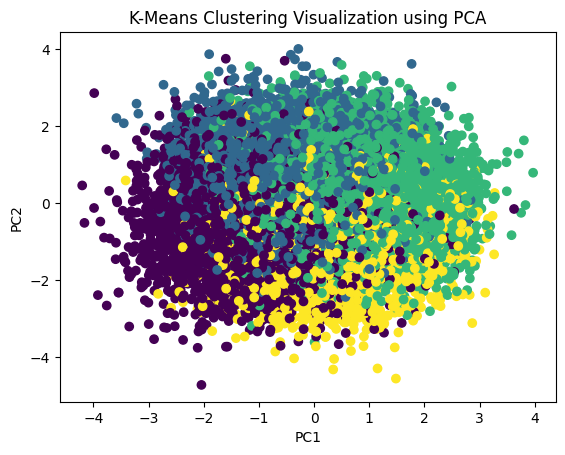

In [78]:
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=pred
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("K-Means Clustering Visualization using PCA")
plt.show()

In [85]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'device_type', 'app_version',
       'sessions_per_week', 'avg_session_duration_min', 'daily_active_minutes',
       'feature_clicks_per_session', 'notifications_opened_per_week',
       'in_app_search_count', 'pages_viewed_per_session',
       'crash_events_last_30_days', 'support_tickets_raised',
       'days_since_last_login', 'subscription_type',
       'ads_clicked_last_30_days', 'content_downloads', 'social_shares',
       'rating_given', 'churn_risk_score', 'engagement_score',
       'account_age_days', 'marketing_source', 'cluster'],
      dtype='object')